# 06 Player ratings

**Objective.** Fit the context baseline, shrink skill, value it in win probability and produce the first PRISM tables.

**Inputs.** player_ratings/output, balls_bat, balls_bowl and rating parquet files written by player_ratings.ratings.run.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import style
from common.io import read_parquet, read_table
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Step 1. Baseline diagnostics, actual against expected

In [2]:
from player_ratings import plots as p3
d = read_table("player_ratings", "baseline_diagnostics.csv")
d[d.phase == "ALL"].round(4)

,role,component,phase,actual,expected,mean_resid,n
0,bat,boundary,ALL,0.1868,0.1872,-0.0004,187016
4,bat,dot,ALL,0.3519,0.3509,0.0009,187016
8,bat,out,ALL,0.0543,0.0557,-0.0014,187016
12,bat,runs,ALL,1.3936,1.3955,-0.0019,187016
16,bowl,boundary,ALL,0.1796,0.1779,0.0017,194482
20,bowl,dot,ALL,0.3384,0.3418,-0.0034,194482
24,bowl,out,ALL,0.0508,0.0560,-0.0052,194482
28,bowl,runs,ALL,1.3904,1.3853,0.0051,194482


## Step 2. Residual check by phase

In [3]:
d.pivot_table(index=["role", "component"], columns="phase", values="mean_resid").round(4)

phase              ALL   DEATH     MID      PP
role component                                
bat  boundary  -0.0004 -0.0013 -0.0006  0.0004
     dot        0.0009 -0.0009  0.0006  0.0028
     out       -0.0014 -0.0025 -0.0017 -0.0002
     runs      -0.0019  0.0029 -0.0077  0.0031
bowl boundary   0.0017  0.0009  0.0014  0.0027
     dot       -0.0034 -0.0056 -0.0036 -0.0015
     out       -0.0052 -0.0085 -0.0058 -0.0021
     runs       0.0051  0.0101 -0.0002  0.0092

## Step 3. Shrinkage constants and what they imply

In [4]:
k = read_table("player_ratings", "shrinkage_constants.csv")
k.round(1)

,role,kN_boundary,tau2_delta_boundary,kD_boundary,kN_dot,tau2_delta_dot,kD_dot,kN_out,tau2_delta_out,kD_out,kN_runs,tau2_delta_runs,kD_runs
0,bat,206.1,0.0,519.0,222.2,0.0,596.8,481.2,0.0,121.9,209.4,0.0,1012.4
1,bowl,400.2,0.0,2000.0,393.5,0.0,365.5,1488.1,0.0,300.1,382.7,0.0,2000.0


## Step 4. Raw and shrunk clutch effects

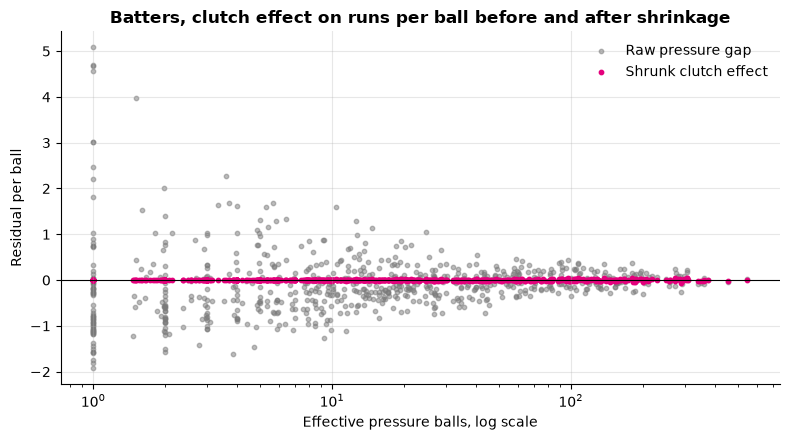

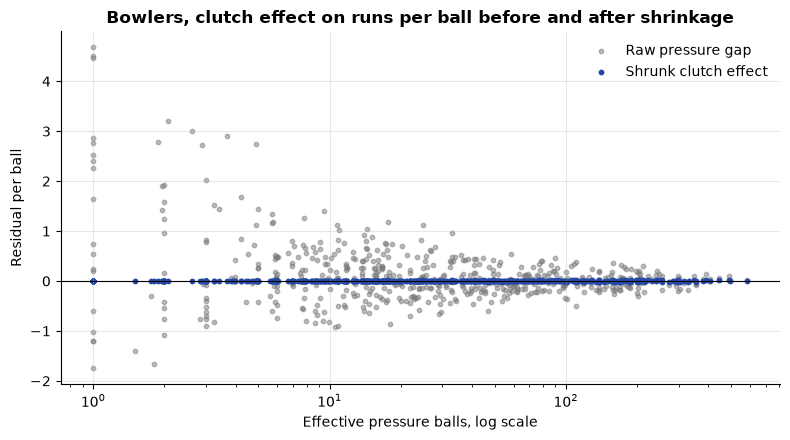

In [5]:
p3.shrinkage("bat"); plt.show()
p3.shrinkage("bowl"); plt.show()

## Step 5. WP value of each outcome on pressure balls

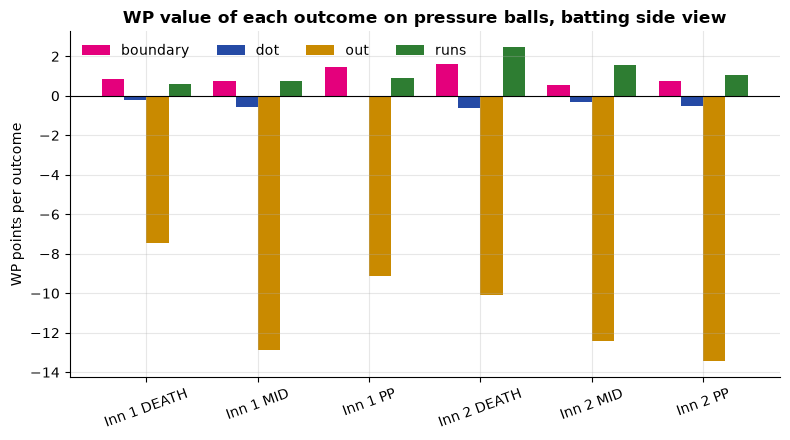

,innings,phase,n,v_boundary,v_dot,v_out,v_runs
0,1,DEATH,5590,-0.54,0.06,7.93,-0.66
1,1,MID,1203,-0.65,0.53,12.88,-0.78
2,1,PP,9,-1.47,0.02,9.15,-0.89
3,2,DEATH,7797,-0.38,0.87,9.79,-2.70
4,2,MID,14588,-0.27,0.36,12.32,-1.61
5,2,PP,9710,-0.37,0.56,13.39,-1.13


In [6]:
p3.component_values("bat"); plt.show()
read_table("player_ratings", "component_values_bowl.csv").round(2)

## Step 6. Opposition adjustment before and after

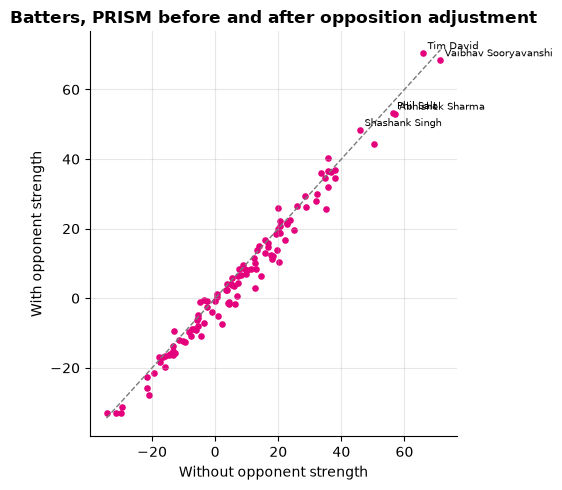

,player_id,player_name,before,after,rank_before,rank_after,rank_change
0,781,Sunil Narine,45.071926,43.004300,1.0,1.0,0.0
1,830,Josh Hazlewood,35.618513,35.033478,2.0,2.0,0.0
2,2933,Jasprit Bumrah,33.758616,30.145984,3.0,3.0,0.0
3,4722,Rashid Khan,33.218879,28.325334,4.0,4.0,0.0
4,6523,Blessing Muzarabani,26.276001,25.615712,5.0,5.0,0.0
5,4219,Krunal Pandya,25.456677,24.340174,7.0,6.0,1.0
6,7920,Nathan Ellis,25.145030,23.974671,8.0,7.0,1.0
7,8661,Matheesha Pathirana,24.331369,22.466868,9.0,8.0,1.0
8,6256,Varun Chakravarthy,26.200526,21.750228,6.0,9.0,-3.0
9,4900,Wanindu Hasaranga,19.656474,18.379032,11.0,10.0,1.0


In [7]:
p3.opposition("bat"); plt.show()
read_table("player_ratings", "opposition_rank_changes_bowl.csv").head(15)

## Step 7. Eligibility pool sizes

In [8]:
read_table("player_ratings", "eligibility_pools.csv")

,role,all_players,min_balls,plus_pressure_balls,plus_pressure_matches,plus_active,with_500_balls
0,bat,881,169,124,121,114,116
1,bowl,640,177,121,117,113,120


## Step 8. First rating tables

In [9]:
for role in ("bat", "bowl"):
    r = read_parquet("player_ratings", f"player_ratings_{role}.parquet")
    display(r[r.eligible].head(15)[["player_name", "teams", "total_balls", "pressure_balls", "prism",
                                     "thetaN_runs", "delta_runs", "thetaP_runs"]].round(3))

,player_name,teams,total_balls,pressure_balls,prism,thetaN_runs,delta_runs,thetaP_runs
0,Tim David,"Australia, Mumbai Indians, Royal Challengers B...",1154,331,70.397,0.190,0.052,0.241
1,Vaibhav Sooryavanshi,"Rajasthan Royals, India, India A",659,103,68.347,0.435,0.038,0.473
2,Phil Salt,"England, Royal Challengers Bengaluru, Kolkata ...",1582,230,53.196,0.222,-0.015,0.207
3,Abhishek Sharma,"Sunrisers Hyderabad, India, India A",2250,321,52.984,0.337,0.005,0.342
4,Shashank Singh,"Punjab Kings, Sunrisers Hyderabad",555,126,48.292,0.039,0.022,0.060
6,Romario Shepherd,"West Indies, Royal Challengers Bengaluru, Sunr...",657,171,44.375,0.167,-0.022,0.145
7,Glenn Maxwell,"Australia, Royal Challengers Bengaluru, Punjab...",903,194,40.413,0.191,-0.000,0.190
10,Rinku Singh,"Kolkata Knight Riders, India",1230,257,36.814,-0.001,0.033,0.032
11,Harry Brook,"England, Sunrisers Hyderabad",832,135,36.667,0.107,0.026,0.133
12,Suryakumar Yadav,"India, Mumbai Indians",2646,528,36.163,0.204,-0.013,0.191


,player_name,teams,total_balls,pressure_balls,prism,thetaN_runs,delta_runs,thetaP_runs
0,Sunil Narine,Kolkata Knight Riders,1482,280,43.004,-0.203,-0.020,-0.222
1,Josh Hazlewood,"Royal Challengers Bengaluru, Australia",1368,362,35.033,-0.029,-0.027,-0.056
3,Jasprit Bumrah,"Mumbai Indians, India",1630,360,30.146,-0.286,0.007,-0.279
4,Rashid Khan,"Gujarat Titans, Afghanistan",2651,448,28.325,-0.102,0.005,-0.097
5,Blessing Muzarabani,"Zimbabwe, Kolkata Knight Riders",820,191,25.616,-0.135,0.013,-0.122
6,Krunal Pandya,"Lucknow Super Giants, Royal Challengers Bengaluru",1227,221,24.340,-0.029,-0.028,-0.056
7,Nathan Ellis,"Australia, Punjab Kings, Chennai Super Kings",858,241,23.975,-0.146,0.014,-0.132
9,Matheesha Pathirana,"Chennai Super Kings, Sri Lanka, Kolkata Knight...",1031,313,22.467,-0.122,0.001,-0.121
10,Varun Chakravarthy,"Kolkata Knight Riders, India",2080,374,21.750,-0.054,-0.021,-0.075
13,Wanindu Hasaranga,"Sri Lanka, Royal Challengers Bengaluru, Rajast...",1950,388,18.379,-0.020,0.014,-0.006


## Key findings

In [10]:
k = read_table("player_ratings", "shrinkage_constants.csv").set_index("role")
pools = read_table("player_ratings", "eligibility_pools.csv").set_index("role")
display(Markdown(f'''
- Normal-level shrinkage for batter runs k is {k.loc["bat", "kN_runs"]:.0f} balls, so a batter with that many normal balls is half his own evidence and half league average.
- Clutch shrinkage for batter runs k is {k.loc["bat", "kD_runs"]:.0f} pressure balls, for bowler runs {k.loc["bowl", "kD_runs"]:.0f}, so clutch moves ratings only a little.
- Bowler wicket skill barely separates players, k {k.loc["bowl", "kN_out"]:.0f} balls.
- {pools.loc["bat", "plus_active"]} batters and {pools.loc["bowl", "plus_active"]} bowlers are eligible.
'''))


- Normal-level shrinkage for batter runs k is 209 balls, so a batter with that many normal balls is half his own evidence and half league average.
- Clutch shrinkage for batter runs k is 1012 pressure balls, for bowler runs 2000, so clutch moves ratings only a little.
- Bowler wicket skill barely separates players, k 1488 balls.
- 114 batters and 113 bowlers are eligible.


## Outputs written

player_ratings/output, balls_bat.parquet, balls_bowl.parquet, player_ratings_bat.parquet, player_ratings_bowl.parquet gitignored. Tables shrinkage_constants, component_values, eligibility_pools, baseline_diagnostics, opposition_rank_changes, ratings. Figures 06_*.png.